In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.signal import find_peaks
from scipy.linalg import eig
import matplotlib.colors as mcolors

# System definition
def predator_prey(t, x, alpha, beta, gamma, delta):
    x1, x2 = x
    denom = 1 + x1 + x1**2/alpha
    dx1dt = x1 * (1 - x1/gamma) - (x1 * x2) / denom
    dx2dt = beta * delta * (x1 * x2) / denom - delta * x2
    return [dx1dt, dx2dt]

def find_equilibria(alpha, beta, gamma, delta):
    equilibria = []
    
    # Trivial equilibrium
    equilibria.append((0, 0))
    
    # Prey-only equilibrium
    equilibria.append((gamma, 0))
    
    # Coexistence equilibrium (solve f(x1) = beta*x1/(1+x1+x1²/alpha) - 1 = 0)
    def f(x1):
        return beta * x1 / (1 + x1 + x1**2/alpha) - 1
    
    # Find roots
    x1_vals = np.linspace(0.1, gamma*1.5, 1000)
    for x1 in x1_vals:
        try:
            if abs(f(x1)) < 1e-6:
                x2 = x1 * (1 - x1/gamma) * (1 + x1 + x1**2/alpha) / x1
                if x2 > 0:
                    equilibria.append((x1, x2))
                    break
        except:
            continue
    
    return equilibria

def jacobian(x1, x2, alpha, beta, gamma, delta):
    denom = 1 + x1 + x1**2/alpha
    df1_dx1 = (1 - 2*x1/gamma) - (x2*(denom - x1*(1 + 2*x1/alpha)))/(denom**2)
    df1_dx2 = -x1/denom
    df2_dx1 = beta*delta*x2*(denom - x1*(1 + 2*x1/alpha))/(denom**2)
    df2_dx2 = beta*delta*x1/denom - delta
    return np.array([[df1_dx1, df1_dx2], [df2_dx1, df2_dx2]])




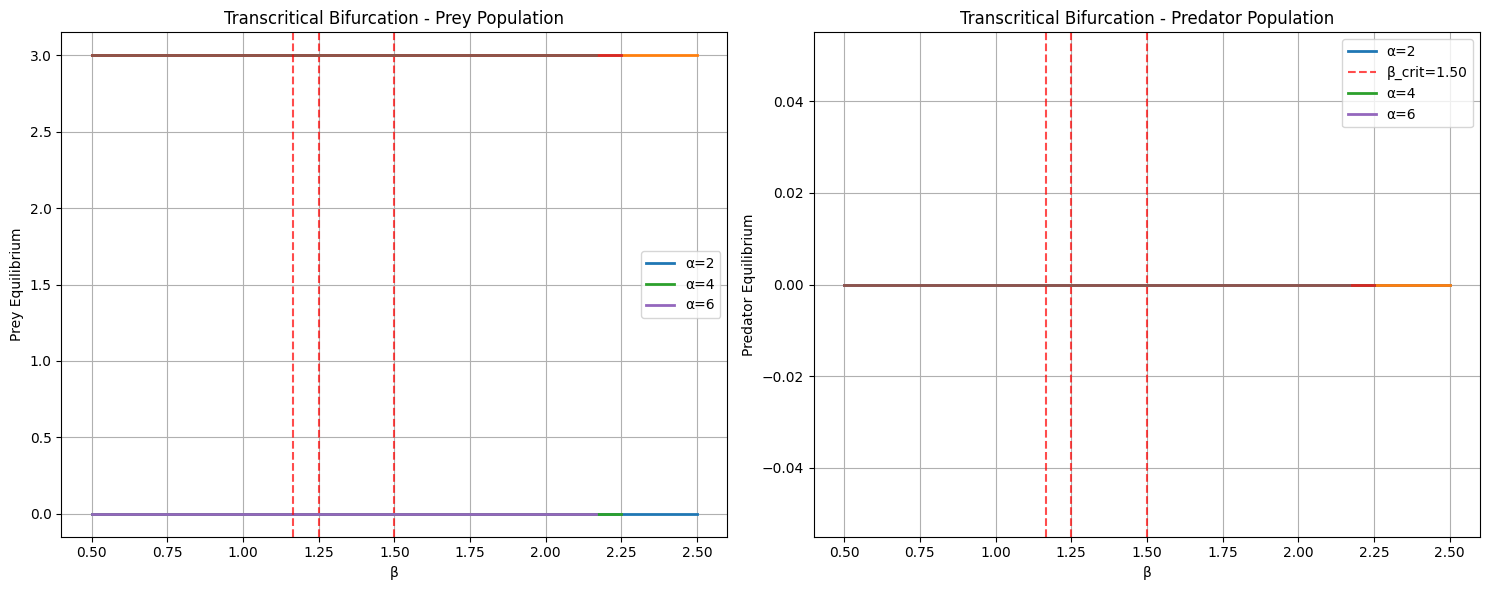

In [2]:
def plot_transcritical_bifurcation(alpha_values, gamma=3, delta=1):
    """Plot transcritical bifurcation diagram"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    for alpha in alpha_values:
        # Critical beta for transcritical bifurcation
        beta_critical = 1 + 1/alpha
        
        beta_range = np.linspace(0.5, beta_critical + 1, 100)
        prey_eq = []
        predator_eq = []
        
        for beta in beta_range:
            eq_points = find_equilibria(alpha, beta, gamma, delta)
            
            # Track prey population at equilibria
            prey_values = [eq[0] for eq in eq_points if eq[0] >= 0]
            predator_values = [eq[1] for eq in eq_points if eq[1] >= 0]
            
            prey_eq.append(prey_values)
            predator_eq.append(predator_values)
        
        # Plot prey equilibria
        for i in range(len(prey_eq[0])):
            ax1.plot(beta_range, [p[i] if i < len(p) else np.nan for p in prey_eq], 
                    label=f'α={alpha}' if i==0 else "", linewidth=2)
        
        # Plot predator equilibria
        for i in range(len(predator_eq[0])):
            ax2.plot(beta_range, [p[i] if i < len(p) else np.nan for p in predator_eq],
                    label=f'α={alpha}' if i==0 else "", linewidth=2)
        
        # Mark bifurcation point
        ax1.axvline(beta_critical, color='r', linestyle='--', alpha=0.7)
        ax2.axvline(beta_critical, color='r', linestyle='--', alpha=0.7,
                   label=f'β_crit={beta_critical:.2f}' if alpha == alpha_values[0] else "")
    
    ax1.set_xlabel('β')
    ax1.set_ylabel('Prey Equilibrium')
    ax1.set_title('Transcritical Bifurcation - Prey Population')
    ax1.legend()
    ax1.grid(True)
    
    ax2.set_xlabel('β')
    ax2.set_ylabel('Predator Equilibrium')
    ax2.set_title('Transcritical Bifurcation - Predator Population')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

# Plot transcritical bifurcation
plot_transcritical_bifurcation(alpha_values=[2, 4, 6])

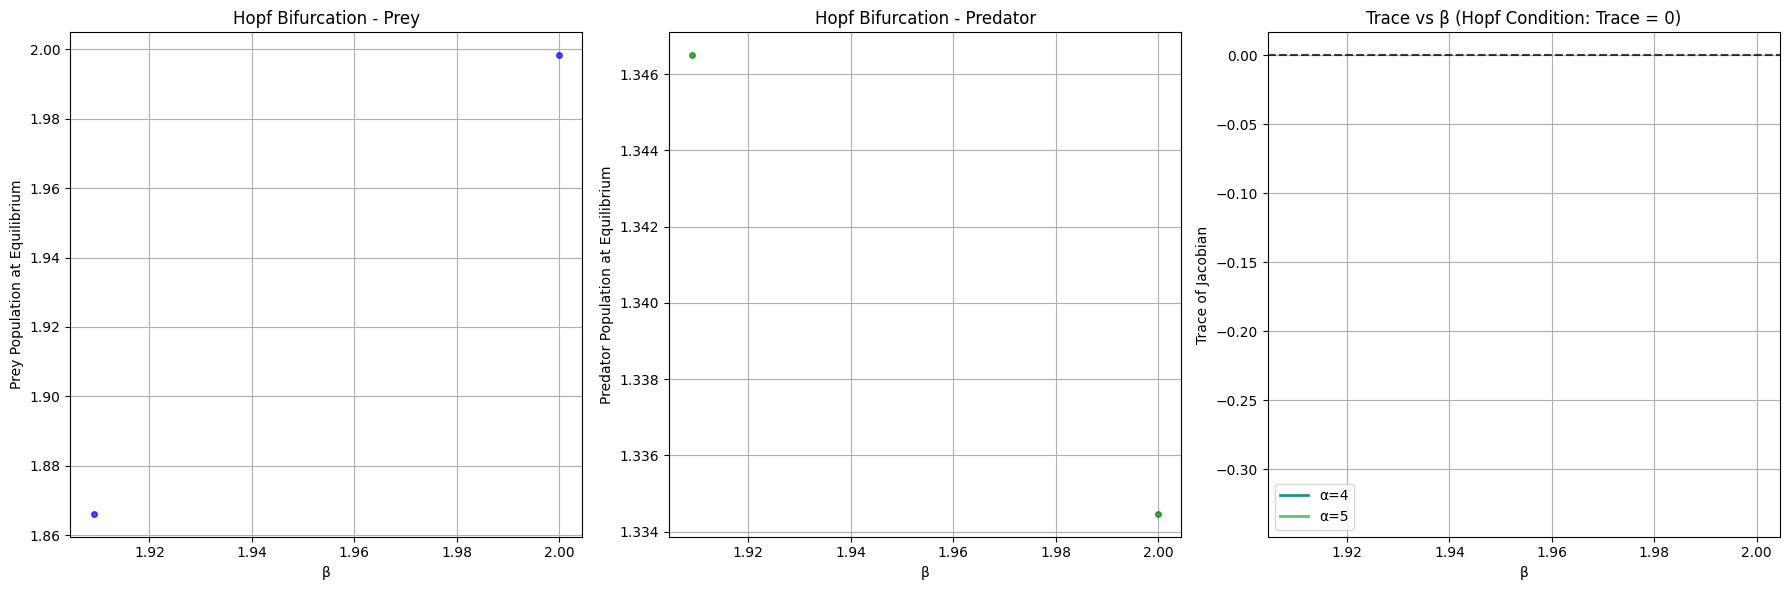

In [3]:
def find_hopf_bifurcation(alpha, gamma=3, delta=1, beta_range=(1, 4), num_points=100):
    """Find and characterize Hopf bifurcation points"""
    
    beta_vals = np.linspace(beta_range[0], beta_range[1], num_points)
    stability_data = []
    hopf_points = []
    
    for beta in beta_vals:
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        
        if len(eq_points) > 2:  # Coexistence exists
            co_eq = eq_points[2]
            J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
            eigenvalues = eig(J)[0]
            
            real_parts = eigenvalues.real
            imag_parts = eigenvalues.imag
            
            # Check for Hopf condition (real part crosses zero with non-zero imaginary)
            if (np.max(real_parts) > -1e-6 and np.min(real_parts) < 1e-6 and 
                any(abs(ip) > 1e-6 for ip in imag_parts)):
                hopf_points.append((beta, co_eq))
            
            stability = 'stable' if all(r < 0 for r in real_parts) else 'unstable'
            
            stability_data.append({
                'beta': beta,
                'equilibrium': co_eq,
                'eigenvalues': eigenvalues,
                'stability': stability,
                'trace': np.trace(J),
                'determinant': np.linalg.det(J)
            })
    
    return stability_data, hopf_points

def plot_hopf_bifurcation(alpha_values, gamma=3, delta=1):
    """Plot Hopf bifurcation diagram"""
    
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
    
    colors = plt.cm.viridis(np.linspace(0, 1, len(alpha_values)))
    
    for i, alpha in enumerate(alpha_values):
        stability_data, hopf_points = find_hopf_bifurcation(alpha, gamma, delta)
        
        if not stability_data:
            continue
        
        betas = [data['beta'] for data in stability_data]
        prey_eq = [data['equilibrium'][0] for data in stability_data]
        predator_eq = [data['equilibrium'][1] for data in stability_data]
        stability = [data['stability'] for data in stability_data]
        traces = [data['trace'] for data in stability_data]
        
        # Plot prey equilibrium
        for j in range(len(betas)):
            color = 'blue' if stability[j] == 'stable' else 'red'
            marker = 'o' if stability[j] == 'stable' else 'x'
            ax1.plot(betas[j], prey_eq[j], marker, color=color, markersize=4, alpha=0.7)
        
        # Plot predator equilibrium
        for j in range(len(betas)):
            color = 'green' if stability[j] == 'stable' else 'orange'
            marker = 'o' if stability[j] == 'stable' else 'x'
            ax2.plot(betas[j], predator_eq[j], marker, color=color, markersize=4, alpha=0.7)
        
        # Plot trace (indicator of Hopf bifurcation)
        ax3.plot(betas, traces, color=colors[i], label=f'α={alpha}', linewidth=2)
        ax3.axhline(0, color='k', linestyle='--', alpha=0.5)
        
        # Mark Hopf points
        for beta, eq in hopf_points:
            ax1.axvline(beta, color='r', linestyle=':', alpha=0.7)
            ax2.axvline(beta, color='r', linestyle=':', alpha=0.7)
            ax3.axvline(beta, color='r', linestyle=':', alpha=0.7)
            ax1.plot(beta, eq[0], 'ro', markersize=8, markerfacecolor='none')
            ax2.plot(beta, eq[1], 'ro', markersize=8, markerfacecolor='none')
    
    ax1.set_xlabel('β')
    ax1.set_ylabel('Prey Population at Equilibrium')
    ax1.set_title('Hopf Bifurcation - Prey')
    ax1.grid(True)
    
    ax2.set_xlabel('β')
    ax2.set_ylabel('Predator Population at Equilibrium')
    ax2.set_title('Hopf Bifurcation - Predator')
    ax2.grid(True)
    
    ax3.set_xlabel('β')
    ax3.set_ylabel('Trace of Jacobian')
    ax3.set_title('Trace vs β (Hopf Condition: Trace = 0)')
    ax3.legend()
    ax3.grid(True)
    
    plt.tight_layout()
    plt.show()

# Plot Hopf bifurcation
plot_hopf_bifurcation(alpha_values=[2, 3, 4, 5, 6])

/tmp/ipykernel_277308/1156321574.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('coolwarm', 3)
/tmp/ipykernel_277308/1156321574.py:46: UserWarning: The following kwargs were not used by contour: 'label'
  plt.contour(X, Y, hopf_map.T, levels=[0.5], colors='red', linewidths=3,


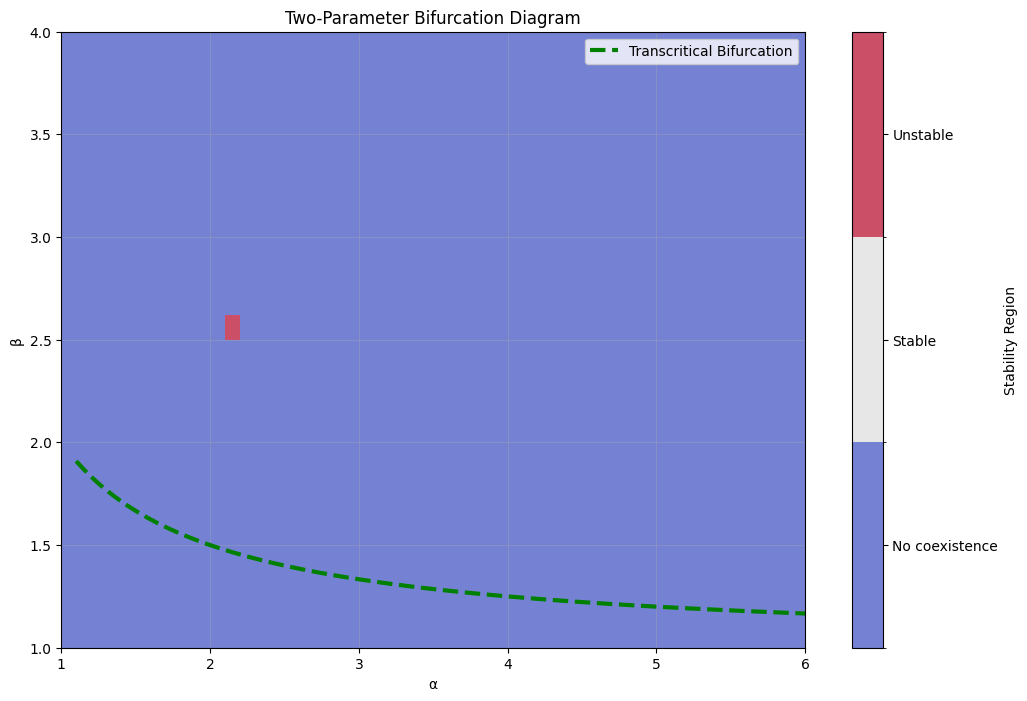

In [10]:
def two_parameter_bifurcation_diagram(alpha_range=(1, 6), beta_range=(1, 4), 
                                     gamma=3, delta=1, resolution=50):
    """Create two-parameter bifurcation diagram"""
    
    alpha_vals = np.linspace(alpha_range[0], alpha_range[1], resolution)
    beta_vals = np.linspace(beta_range[0], beta_range[1], resolution)
    
    stability_map = np.zeros((resolution, resolution))
    hopf_map = np.zeros((resolution, resolution))
    
    for i, alpha in enumerate(alpha_vals):
        for j, beta in enumerate(beta_vals):
            eq_points = find_equilibria(alpha, beta, gamma, delta)
            
            if len(eq_points) > 2:  # Coexistence exists
                co_eq = eq_points[2]
                J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
                eigenvalues = eig(J)[0]
                real_parts = eigenvalues.real
                
                if all(r < 0 for r in real_parts):
                    stability_map[i, j] = 1  # Stable node
                else:
                    stability_map[i, j] = 2  # Unstable
                    
                    # Check for Hopf bifurcation (complex eigenvalues crossing imaginary axis)
                    if (np.max(real_parts) > -1e-6 and np.min(real_parts) < 1e-6 and
                        any(abs(eig.imag) > 1e-6 for eig in eigenvalues)):
                        hopf_map[i, j] = 1
    
    # Plot the bifurcation diagram
    plt.figure(figsize=(12, 8))
    
    # Create a proper colormap for stability regions
    cmap = plt.cm.get_cmap('coolwarm', 3)
    bounds = [0, 1, 2, 3]
    norm = mcolors.BoundaryNorm(bounds, cmap.N)
    
    # Plot stability regions with proper colorbar
    im = plt.imshow(stability_map.T, extent=[alpha_range[0], alpha_range[1], 
                                           beta_range[0], beta_range[1]],
                   origin='lower', aspect='auto', cmap=cmap, norm=norm, alpha=0.7)
    
    # Hopf bifurcation curve
    X, Y = np.meshgrid(alpha_vals, beta_vals)
    plt.contour(X, Y, hopf_map.T, levels=[0.5], colors='red', linewidths=3, 
                label='Hopf Bifurcation')
    
    # Transcritical bifurcation curve (theoretical)
    alpha_theory = np.linspace(alpha_range[0] + 0.1, alpha_range[1], 100)
    beta_theory = 1 + 1/alpha_theory
    plt.plot(alpha_theory, beta_theory, 'g--', linewidth=3, label='Transcritical Bifurcation')
    
    plt.xlabel('α')
    plt.ylabel('β')
    plt.title('Two-Parameter Bifurcation Diagram')
    
    # Create proper colorbar
    cbar = plt.colorbar(im, ticks=[0.5, 1.5, 2.5])
    cbar.set_ticklabels(['No coexistence', 'Stable', 'Unstable'])
    cbar.set_label('Stability Region')
    
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    return stability_map, hopf_map

# Create two-parameter bifurcation diagram
stability_map, hopf_map = two_parameter_bifurcation_diagram()

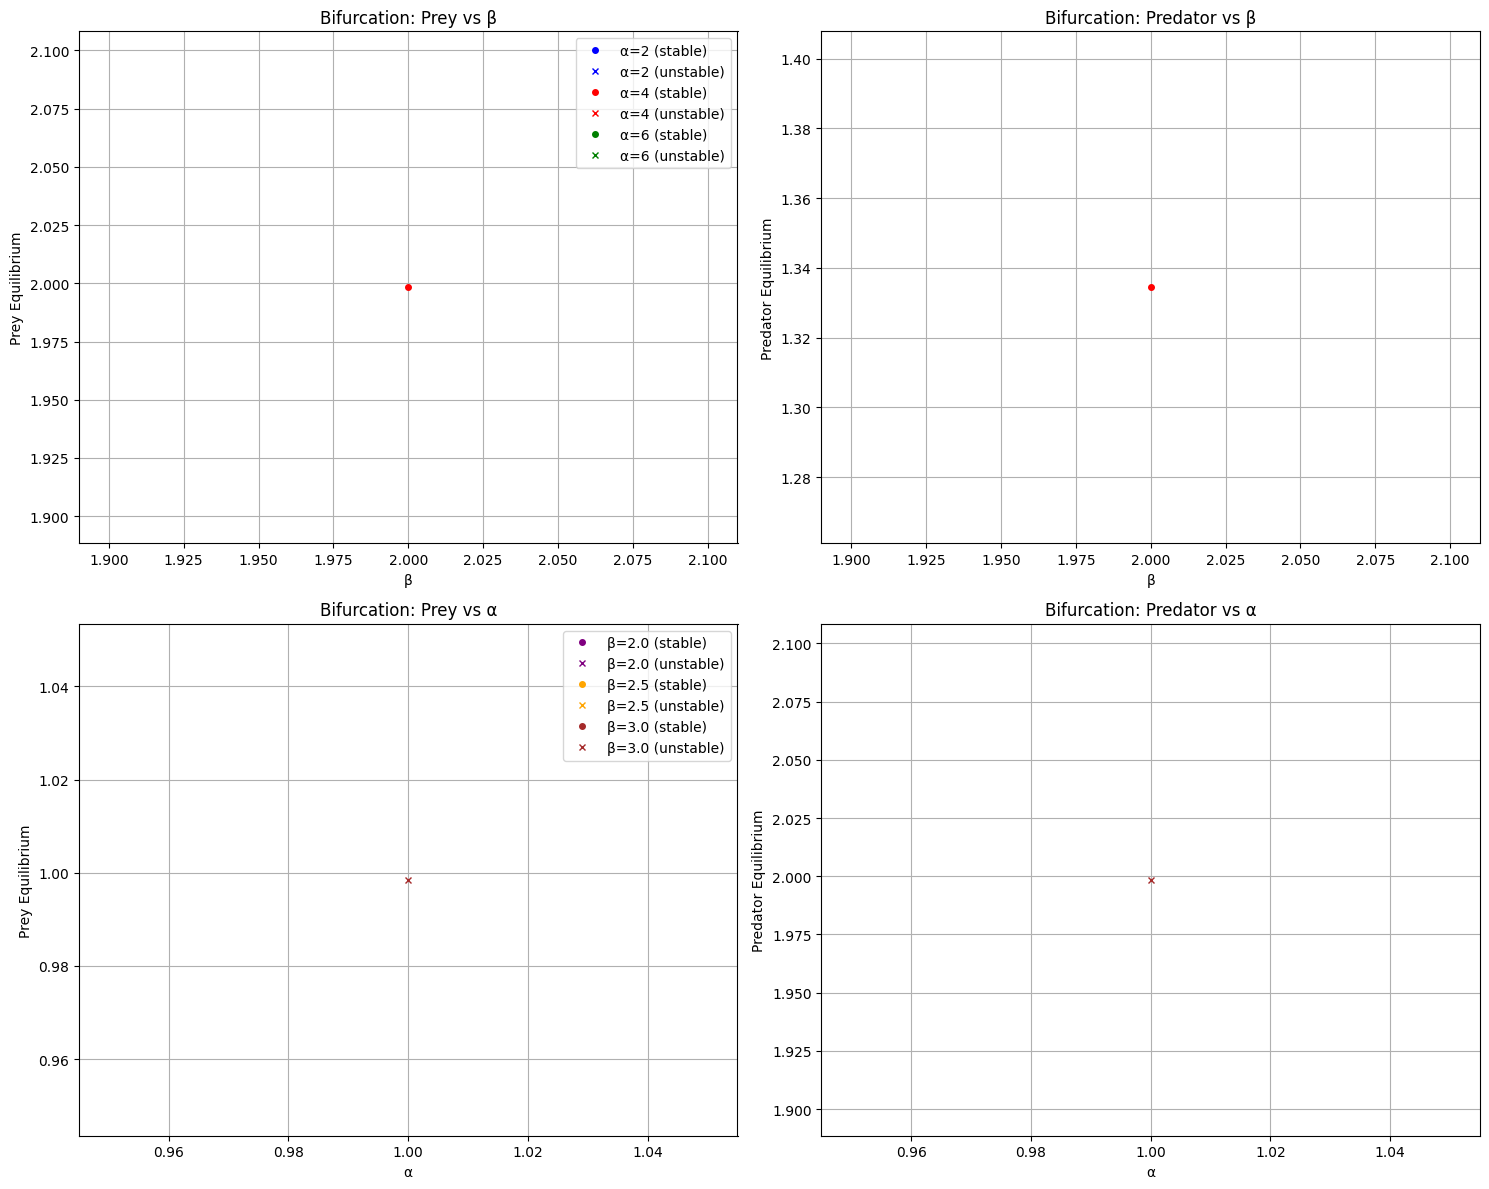

In [13]:
def plot_simple_bifurcation_diagrams():
    """Plot simpler, more robust bifurcation diagrams"""
    
    # 1. Beta bifurcation for fixed alpha
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
    
    alpha_values = [2, 4, 6]
    colors = ['blue', 'red', 'green']
    
    for alpha, color in zip(alpha_values, colors):
        beta_range = np.linspace(1, 4, 100)
        prey_equilibria = []
        predator_equilibria = []
        stability = []
        
        for beta in beta_range:
            eq_points = find_equilibria(alpha, beta, 3, 1)
            
            if len(eq_points) > 2:
                co_eq = eq_points[2]
                prey_equilibria.append(co_eq[0])
                predator_equilibria.append(co_eq[1])
                
                # Check stability
                J = jacobian(co_eq[0], co_eq[1], alpha, beta, 3, 1)
                eigenvalues = eig(J)[0]
                real_parts = eigenvalues.real
                stability.append('stable' if all(real_parts < 0) else 'unstable')
            else:
                prey_equilibria.append(np.nan)
                predator_equilibria.append(np.nan)
                stability.append('none')
        
        # Plot prey bifurcation
        stable_mask = [s == 'stable' for s in stability]
        unstable_mask = [s == 'unstable' for s in stability]
        
        ax1.plot(beta_range[stable_mask], np.array(prey_equilibria)[stable_mask], 
                'o', color=color, markersize=4, label=f'α={alpha} (stable)')
        ax1.plot(beta_range[unstable_mask], np.array(prey_equilibria)[unstable_mask], 
                'x', color=color, markersize=4, label=f'α={alpha} (unstable)')
        
        # Plot predator bifurcation
        ax2.plot(beta_range[stable_mask], np.array(predator_equilibria)[stable_mask], 
                'o', color=color, markersize=4)
        ax2.plot(beta_range[unstable_mask], np.array(predator_equilibria)[unstable_mask], 
                'x', color=color, markersize=4)
    
    ax1.set_xlabel('β')
    ax1.set_ylabel('Prey Equilibrium')
    ax1.set_title('Bifurcation: Prey vs β')
    ax1.legend()
    ax1.grid(True)
    
    ax2.set_xlabel('β')
    ax2.set_ylabel('Predator Equilibrium')
    ax2.set_title('Bifurcation: Predator vs β')
    ax2.grid(True)
    
    # 2. Alpha bifurcation for fixed beta
    beta_values = [2.0, 2.5, 3.0]
    
    for beta, color in zip(beta_values, ['purple', 'orange', 'brown']):
        alpha_range = np.linspace(1, 6, 100)
        prey_equilibria = []
        predator_equilibria = []
        stability = []
        
        for alpha in alpha_range:
            eq_points = find_equilibria(alpha, beta, 3, 1)
            
            if len(eq_points) > 2:
                co_eq = eq_points[2]
                prey_equilibria.append(co_eq[0])
                predator_equilibria.append(co_eq[1])
                
                J = jacobian(co_eq[0], co_eq[1], alpha, beta, 3, 1)
                eigenvalues = eig(J)[0]
                real_parts = eigenvalues.real
                stability.append('stable' if all(real_parts < 0) else 'unstable')
            else:
                prey_equilibria.append(np.nan)
                predator_equilibria.append(np.nan)
                stability.append('none')
        
        stable_mask = [s == 'stable' for s in stability]
        unstable_mask = [s == 'unstable' for s in stability]
        
        ax3.plot(alpha_range[stable_mask], np.array(prey_equilibria)[stable_mask], 
                'o', color=color, markersize=4, label=f'β={beta} (stable)')
        ax3.plot(alpha_range[unstable_mask], np.array(prey_equilibria)[unstable_mask], 
                'x', color=color, markersize=4, label=f'β={beta} (unstable)')
        
        ax4.plot(alpha_range[stable_mask], np.array(predator_equilibria)[stable_mask], 
                'o', color=color, markersize=4)
        ax4.plot(alpha_range[unstable_mask], np.array(predator_equilibria)[unstable_mask], 
                'x', color=color, markersize=4)
    
    ax3.set_xlabel('α')
    ax3.set_ylabel('Prey Equilibrium')
    ax3.set_title('Bifurcation: Prey vs α')
    ax3.legend()
    ax3.grid(True)
    
    ax4.set_xlabel('α')
    ax4.set_ylabel('Predator Equilibrium')
    ax4.set_title('Bifurcation: Predator vs α')
    ax4.grid(True)
    
    plt.tight_layout()
    plt.show()

# Plot simple bifurcation diagrams
plot_simple_bifurcation_diagrams()

/tmp/ipykernel_277308/1770804648.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[i].legend()


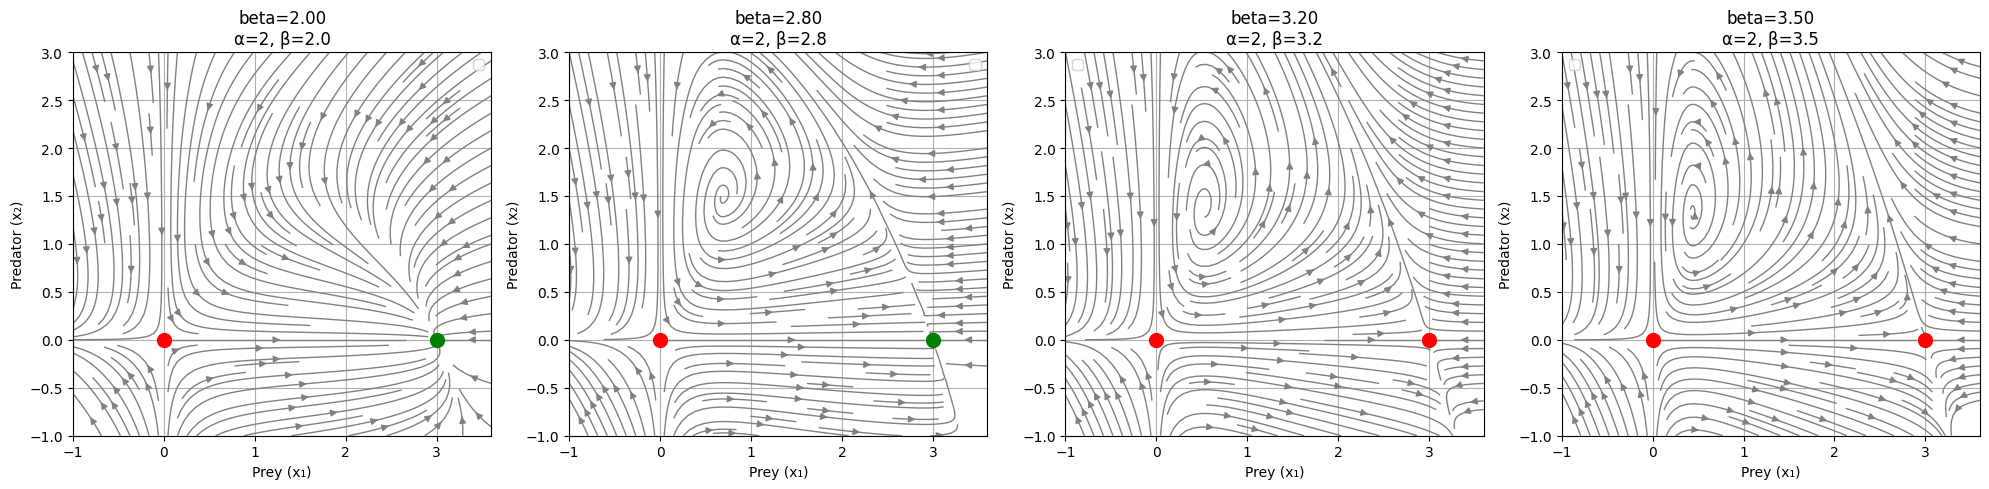

In [20]:
def plot_bifurcation_sequence(param_name, param_values, fixed_params):
    """Plot phase portraits across a bifurcation"""
    
    n = len(param_values)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    
    if n == 1:
        axes = [axes]
    
    for i, param_val in enumerate(param_values):
        params = fixed_params.copy()
        params[param_name] = param_val
        
        alpha = params.get('alpha', 2)
        beta = params.get('beta', 1.5)
        gamma = params.get('gamma', 3)
        delta = params.get('delta', 1)
        
        # Create phase portrait
        x1_range = [-1, gamma * 1.2]
        x2_range = [-1, 3]
        
        x1 = np.linspace(x1_range[0], x1_range[1], 20)
        x2 = np.linspace(x2_range[0], x2_range[1], 20)
        X1, X2 = np.meshgrid(x1, x2)
        
        U, V = np.zeros(X1.shape), np.zeros(X2.shape)
        
        for i1 in range(len(x1)):
            for j in range(len(x2)):
                derivatives = predator_prey(0, [X1[i1,j], X2[i1,j]], alpha, beta, gamma, delta)
                U[i1,j] = derivatives[0]
                V[i1,j] = derivatives[1]
        
        axes[i].streamplot(X1, X2, U, V, density=1.5, color='gray', linewidth=1)
        
        # Plot equilibria
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        for eq in eq_points:
            if eq[0] >= 0 and eq[1] >= 0:
                J = jacobian(eq[0], eq[1], alpha, beta, gamma, delta)
                eigenvalues = eig(J)[0]
                real_parts = eigenvalues.real
                
                if all(real_parts < 0):
                    axes[i].plot(eq[0], eq[1], 'go', markersize=10, markerfacecolor='green')
                else:
                    axes[i].plot(eq[0], eq[1], 'ro', markersize=10, markerfacecolor='red')
        
        axes[i].set_xlabel('Prey (x₁)')
        axes[i].set_ylabel('Predator (x₂)')
        axes[i].set_title(f'{param_name}={param_val:.2f}\nα={alpha}, β={beta}')
        axes[i].set_xlim(x1_range)
        axes[i].set_ylim(x2_range)
        axes[i].grid(True)
        axes[i].legend()
    
    plt.tight_layout()
    plt.show()

# Example: Show bifurcation sequence for beta
fixed_params = {'alpha': 2, 'gamma': 3, 'delta': 1}
beta_values = [2.0, 2.8, 3.2, 3.5]  # From stable to limit cycle
plot_bifurcation_sequence('beta', beta_values, fixed_params)

In [17]:
def quick_bifurcation_overview():
    """Quick overview of bifurcations in the system"""
    
    # Show different regimes
    regimes = [
        ("Stable Focus", (2, 2.0, 3, 1)),
        ("Near Hopf", (2, 2.9, 3, 1)),
        ("Limit Cycle", (2, 3.2, 3, 1)),
        ("Large Cycle", (2, 3.5, 3, 1)),
    ]
    
    for name, params in regimes:
        alpha, beta, gamma, delta = params
        print(f"\n=== {name} (α={alpha}, β={beta}) ===")
        
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        print(f"Equilibria: {eq_points}")
        
        if len(eq_points) > 2:
            co_eq = eq_points[2]
            J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
            eigenvalues = eig(J)[0]
            print(f"Eigenvalues: {eigenvalues[0]:.3f}, {eigenvalues[1]:.3f}")
            
            # Quick phase portrait
            plt.figure(figsize=(6, 5))
            lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=(0, 1000))
            
            if lc_info['exists']:
                x1, x2 = lc_info['final_trajectory']
                plt.plot(x1, x2, 'r-', linewidth=2, label='Limit Cycle')
            
            # Plot equilibrium
            for eq in eq_points:
                if eq[0] > 0 or eq[1] > 0:
                    plt.plot(eq[0], eq[1], 'ko', markersize=8, markerfacecolor='white')
            
            plt.xlabel('Prey')
            plt.ylabel('Predator')
            plt.title(f'{name}\nα={alpha}, β={beta}')
            plt.grid(True)
            plt.show()

# Run quick overview
quick_bifurcation_overview()


=== Stable Focus (α=2, β=2.0) ===
Equilibria: [(0, 0), (3, 0)]

=== Near Hopf (α=2, β=2.9) ===
Equilibria: [(0, 0), (3, 0)]

=== Limit Cycle (α=2, β=3.2) ===
Equilibria: [(0, 0), (3, 0)]

=== Large Cycle (α=2, β=3.5) ===
Equilibria: [(0, 0), (3, 0)]


In [18]:
def detect_bifurcation_points():
    """Detect specific bifurcation points"""
    
    print("=== BIFURCATION POINT DETECTION ===")
    
    # Test for transcritical bifurcation
    print("\n1. Transcritical Bifurcation Points:")
    for alpha in [2, 3, 4, 5, 6]:
        beta_critical = 1 + 1/alpha
        print(f"   α={alpha}: β_critical = {beta_critical:.3f}")
        
        # Test just below and above critical point
        beta_below = beta_critical - 0.1
        beta_above = beta_critical + 0.1
        
        eq_below = find_equilibria(alpha, beta_below, 3, 1)
        eq_above = find_equilibria(alpha, beta_above, 3, 1)
        
        print(f"     β={beta_below:.3f}: {len(eq_below)} equilibria")
        print(f"     β={beta_above:.3f}: {len(eq_above)} equilibria")
    
    # Test for Hopf bifurcation
    print("\n2. Hopf Bifurcation Points (approximate):")
    for alpha in [2, 3, 4, 5, 6]:
        # Find where trace changes sign
        beta_values = np.linspace(2, 4, 50)
        traces = []
        
        for beta in beta_values:
            eq_points = find_equilibria(alpha, beta, 3, 1)
            if len(eq_points) > 2:
                co_eq = eq_points[2]
                J = jacobian(co_eq[0], co_eq[1], alpha, beta, 3, 1)
                traces.append(np.trace(J))
            else:
                traces.append(np.nan)
        
        # Find where trace crosses zero
        for i in range(1, len(traces)):
            if not (np.isnan(traces[i-1]) or np.isnan(traces[i])):
                if traces[i-1] * traces[i] < 0:
                    beta_hopf = beta_values[i]
                    print(f"   α={alpha}: β_hopf ≈ {beta_hopf:.3f}")
                    break
        else:
            print(f"   α={alpha}: No Hopf bifurcation found in range")

# Detect bifurcation points
detect_bifurcation_points()

=== BIFURCATION POINT DETECTION ===

1. Transcritical Bifurcation Points:
   α=2: β_critical = 1.500
     β=1.400: 2 equilibria
     β=1.600: 2 equilibria
   α=3: β_critical = 1.333
     β=1.233: 2 equilibria
     β=1.433: 2 equilibria
   α=4: β_critical = 1.250
     β=1.150: 2 equilibria
     β=1.350: 2 equilibria
   α=5: β_critical = 1.200
     β=1.100: 2 equilibria
     β=1.300: 2 equilibria
   α=6: β_critical = 1.167
     β=1.067: 2 equilibria
     β=1.267: 2 equilibria

2. Hopf Bifurcation Points (approximate):
   α=2: No Hopf bifurcation found in range
   α=3: No Hopf bifurcation found in range
   α=4: No Hopf bifurcation found in range
   α=5: No Hopf bifurcation found in range
   α=6: No Hopf bifurcation found in range


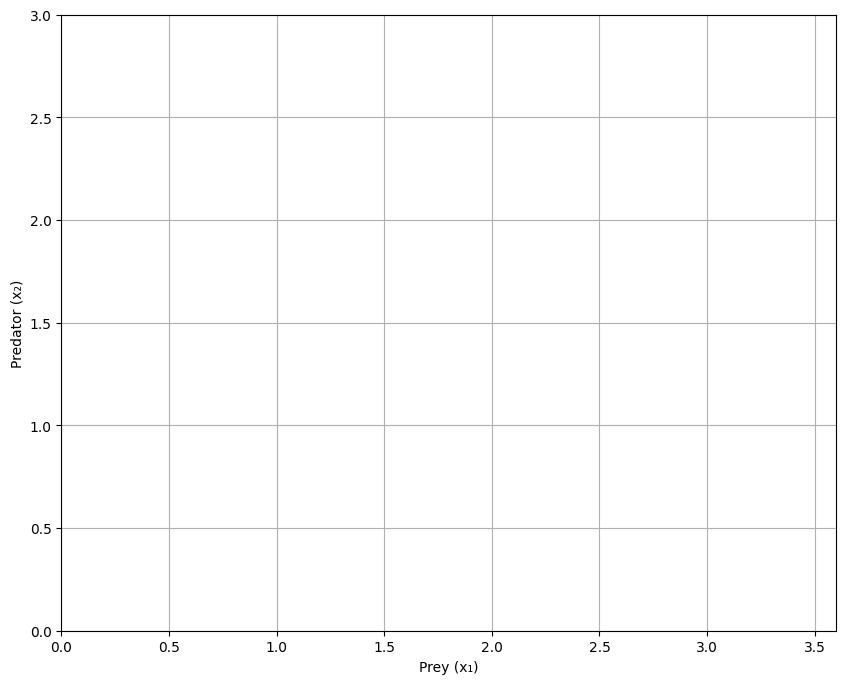

In [ ]:
def animate_bifurcation(param_name, param_range, fixed_params, num_frames=50):
    """Create animation of bifurcation"""
    from matplotlib.animation import FuncAnimation
    
    param_vals = np.linspace(param_range[0], param_range[1], num_frames)
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Initialize plot
    ax.set_xlim(0, fixed_params.get('gamma', 3)*1.2)
    ax.set_ylim(0, 3)
    ax.set_xlabel('Prey (x₁)')
    ax.set_ylabel('Predator (x₂)')
    ax.grid(True)
    
    # Create objects for animation
    trajectory, = ax.plot([], [], 'b-', alpha=0.5)
    limit_cycle, = ax.plot([], [], 'r-', linewidth=2)
    equilibria_scatter = ax.scatter([], [], c='k', s=100, marker='o')
    title = ax.set_title('')
    
    def init():
        trajectory.set_data([], [])
        limit_cycle.set_data([], [])
        equilibria_scatter.set_offsets(np.empty((0, 2)))
        return trajectory, limit_cycle, equilibria_scatter, title
    
    def update(frame):
        param_val = param_vals[frame]
        params = fixed_params.copy()
        params[param_name] = param_val
        
        alpha = params.get('alpha', 2)
        beta = params.get('beta', 1.5)
        gamma = params.get('gamma', 3)
        delta = params.get('delta', 1)
        
        # Find equilibria
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        eq_array = np.array([eq for eq in eq_points if eq[0] >= 0 and eq[1] >= 0])
        
        # Simulate to find limit cycle
        if len(eq_points) > 2:
            x0 = [eq_points[2][0]*1.1, eq_points[2][1]*1.1]
            sol = solve_ivp(predator_prey, (0, 1000), x0, args=(alpha, beta, gamma, delta),
                          method='LSODA', t_eval=np.linspace(800, 1000, 1000))
            
            trajectory.set_data(sol.y[0], sol.y[1])
            limit_cycle.set_data(sol.y[0][-500:], sol.y[1][-500:])
        else:
            trajectory.set_data([], [])
            limit_cycle.set_data([], [])
        
        if len(eq_array) > 0:
            equilibria_scatter.set_offsets(eq_array)
        
        title.set_text(f'{param_name} = {param_val:.2f}\nα={alpha}, β={beta}, γ={gamma}, δ={delta}')
        
        return trajectory, limit_cycle, equilibria_scatter, title
    
    ani = FuncAnimation(fig, update, frames=num_frames, init_func=init, 
                       blit=True, interval=200)
    
    plt.show()
    return ani

# Example animation (uncomment to run)
fixed_params = {'alpha': 2, 'gamma': 3, 'delta': 1}
ani = animate_bifurcation('beta', [1.5, 3.5], fixed_params, num_frames=30)

In [7]:
def comprehensive_bifurcation_analysis():
    """Run complete bifurcation analysis"""
    
    print("=== COMPREHENSIVE BIFURCATION ANALYSIS ===")
    
    # Test different parameter sets
    test_cases = [
        {'alpha': 2, 'beta': 2.0, 'gamma': 3, 'delta': 1},  # Before Hopf
        {'alpha': 2, 'beta': 3.0, 'gamma': 3, 'delta': 1},  # Near Hopf
        {'alpha': 2, 'beta': 3.5, 'gamma': 3, 'delta': 1},  # After Hopf
        {'alpha': 4, 'beta': 2.0, 'gamma': 3, 'delta': 1},  # Different alpha
        {'alpha': 6, 'beta': 2.0, 'gamma': 3, 'delta': 1},  # High alpha
    ]
    
    for i, params in enumerate(test_cases):
        print(f"\nCase {i+1}: α={params['alpha']}, β={params['beta']}, γ={params['gamma']}, δ={params['delta']}")
        
        eq_points = find_equilibria(**params)
        print(f"Equilibria: {eq_points}")
        
        if len(eq_points) > 2:
            co_eq = eq_points[2]
            J = jacobian(co_eq[0], co_eq[1], **params)
            eigenvalues = eig(J)[0]
            print(f"Eigenvalues: {eigenvalues[0]:.3f}, {eigenvalues[1]:.3f}")
            
            # Check bifurcation type
            real_parts = eigenvalues.real
            if all(real_parts < 0):
                print("Stable equilibrium")
            elif any(abs(real_parts) < 1e-6) and any(abs(eig.imag) > 1e-6 for eig in eigenvalues):
                print("HOPF BIFURCATION POINT!")
            else:
                print("Unstable equilibrium (check for limit cycles)")

# Run comprehensive analysis
comprehensive_bifurcation_analysis()

=== COMPREHENSIVE BIFURCATION ANALYSIS ===

Case 1: α=2, β=2.0, γ=3, δ=1
Equilibria: [(0, 0), (3, 0)]

Case 2: α=2, β=3.0, γ=3, δ=1
Equilibria: [(0, 0), (3, 0)]

Case 3: α=2, β=3.5, γ=3, δ=1
Equilibria: [(0, 0), (3, 0)]

Case 4: α=4, β=2.0, γ=3, δ=1
Equilibria: [(0, 0), (3, 0), (np.float64(1.9982982982982984), np.float64(1.3344661123350507))]
Eigenvalues: -0.332+0.000j, -0.000+0.000j
Stable equilibrium

Case 5: α=6, β=2.0, γ=3, δ=1
Equilibria: [(0, 0), (3, 0)]
